# Polynomial regression: predicting ice cream sales

The previous notebook introduced a straight-line regression model. Here we use a
different practice dataset to learn how polynomial features can model a curved
relationship between temperature and ice cream sales.

For a degree-2 model, the prediction is

$$\hat{y} = b_0 + b_1T + b_2T^2,$$

where $T$ is temperature in degrees Celsius and $\hat{y}$ is predicted sales in
units. We still use `LinearRegression`: the prediction is linear in the learned
coefficients $b_0$, $b_1$, and $b_2$, even though it is curved with respect to $T$.

We will load and inspect the data, keep a test set aside, compare a straight line
with a quadratic curve, and interpret their mean absolute errors.

## 1. Load the practice dataset

This notebook requires `numpy`, `pandas`, `matplotlib`, and `scikit-learn`.
Start the kernel from the `How-To-ML` repository root or any folder inside it.
The next cell searches that folder and its parents for the CSV, so it also works
when the kernel starts in this notebook's folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

In [2]:
for candidate in (Path.cwd(), *Path.cwd().parents):
    data_path = candidate / "trainingdata" / "Ice_cream selling_data.csv"
    if data_path.is_file():
        break
else:
    raise FileNotFoundError(
        "Could not find trainingdata/Ice_cream selling_data.csv. "
        "Start the notebook kernel from the How-To-ML repository root "
        "or a folder inside it."
    )

df = pd.read_csv(data_path)
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [3]:
print(f"Observations: {len(df)}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.describe()

Observations: 49
Missing values: 0
Duplicate rows: 0


,Temperature (°C),Ice Cream Sales (units)
count,49.000000,49.000000
mean,0.271755,15.905308
std,2.697672,12.264682
min,-4.662263,0.328626
25%,-2.111870,4.857988
50%,0.688781,12.615181
75%,2.784836,25.142082
max,4.899032,41.842986


## 2. Inspect the relationship

`X` contains one input feature, temperature; `y` contains the sales to predict.
Scikit-learn expects `X` to have shape `(observations, features)`, so we select
temperature with double brackets. A single target can remain one-dimensional.

The scatter plot shows the observed relationship. This small practice dataset
has a curved pattern, with higher sales at both ends of its temperature range.
Treat that pattern as a feature of this dataset, rather than a general rule
about real ice cream demand.

In [4]:
X = df[["Temperature (°C)"]].to_numpy()
y = df["Ice Cream Sales (units)"].to_numpy()

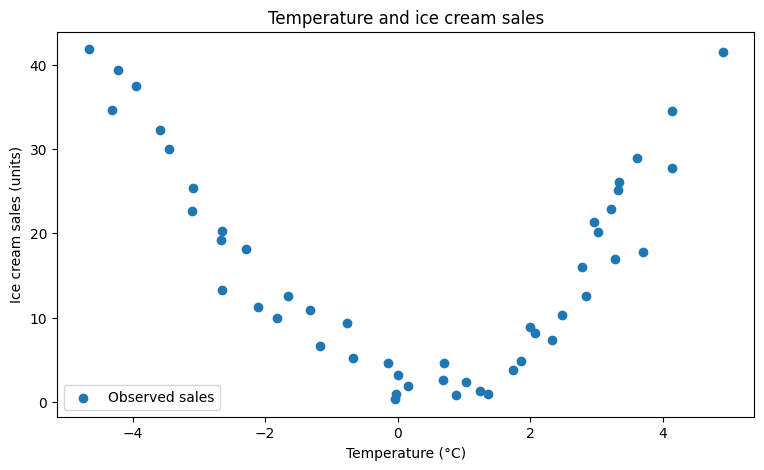

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(X[:, 0], y, color="tab:blue", label="Observed sales")
plt.xlabel("Temperature (°C)")
plt.ylabel("Ice cream sales (units)")
plt.title("Temperature and ice cream sales")
plt.legend()
plt.show()

## 3. Keep a test set aside

We use 75% of the observations to train both models and the remaining 25% to
evaluate them. `random_state=42` makes the split repeatable. Both models use the
same split, so their errors can be compared fairly.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 36
Test observations: 13


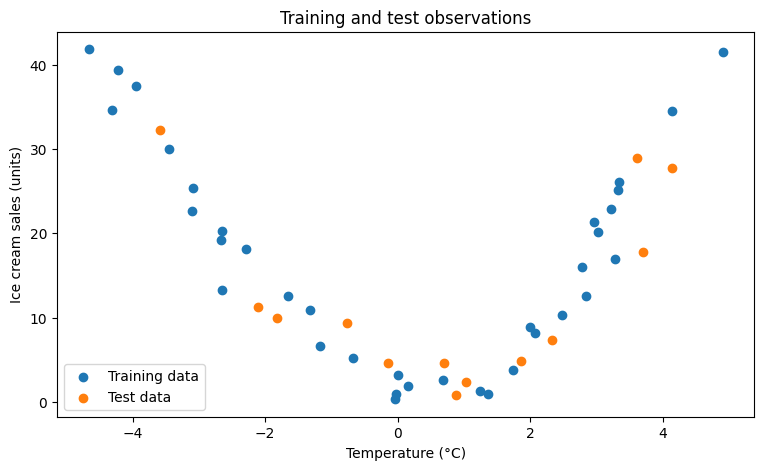

In [7]:
plt.figure(figsize=(9, 5))
plt.scatter(X_train[:, 0], y_train, color="tab:blue", label="Training data")
plt.scatter(X_test[:, 0], y_test, color="tab:orange", label="Test data")
plt.xlabel("Temperature (°C)")
plt.ylabel("Ice cream sales (units)")
plt.title("Training and test observations")
plt.legend()
plt.show()

## 4. Fit a straight line and a quadratic model

The straight-line model is our baseline. For the quadratic model,
`PolynomialFeatures(degree=2, include_bias=False)` expands each temperature $T$
into two features, $T$ and $T^2$. `LinearRegression` supplies the intercept $b_0$,
so we do not need an extra constant column.

Fit the feature transformer once on `X_train`, then reuse `transform` for test
data and new temperatures. Do not fit it again on the expanded features: that
would change the number of input columns it expects.

Degree 2 is chosen for this demonstration. If comparing several degrees, choose
one using cross-validation within the training set and reserve the test set for
the final evaluation.

In [8]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [9]:
polynomial_features = PolynomialFeatures(degree=2, include_bias=False)
x_poly_train = polynomial_features.fit_transform(X_train)
x_poly_test = polynomial_features.transform(X_test)

model = LinearRegression()
model.fit(x_poly_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## 5. Compare prediction errors

Mean absolute error (MAE) is the average absolute difference between predicted
and observed sales. It is measured in sales units, and a lower value is better.
Training MAE describes the fit to observations used for learning; test MAE
describes performance on the held-out observations.

In [10]:
y_pred = model.predict(x_poly_test)
y_pred_train = model.predict(x_poly_train)
linear_pred = linear_model.predict(X_test)
linear_pred_train = linear_model.predict(X_train)

results = pd.DataFrame(
    {
        "Train MAE (units)": [
            mean_absolute_error(y_train, linear_pred_train),
            mean_absolute_error(y_train, y_pred_train),
        ],
        "Test MAE (units)": [
            mean_absolute_error(y_test, linear_pred),
            mean_absolute_error(y_test, y_pred),
        ],
    },
    index=["Linear regression", "Polynomial regression (degree 2)"],
)
results.round(3)

,Train MAE (units),Test MAE (units)
Linear regression,10.254,11.054
Polynomial regression (degree 2),2.608,3.172


For this fixed split, the quadratic model has a training MAE of about **2.608
units** and a test MAE of about **3.172 units**. On the 13 held-out observations,
its predictions differ from observed sales by about 3.17 units on average.
The straight-line baseline has a test MAE of about **11.054 units**.

The quadratic model captures this dataset's curved pattern better. The test
error is slightly higher than the training error, but one small split is not
enough to make a strong claim about generalization or the absence of overfitting.
These results also do not establish performance outside this practice dataset.

## 6. Visualize the fitted models

A sorted grid of temperatures produces smooth prediction lines. Plotting the
randomly ordered test observations as a connected line would produce a zigzag.
The grid stays within the temperature range observed in the dataset.

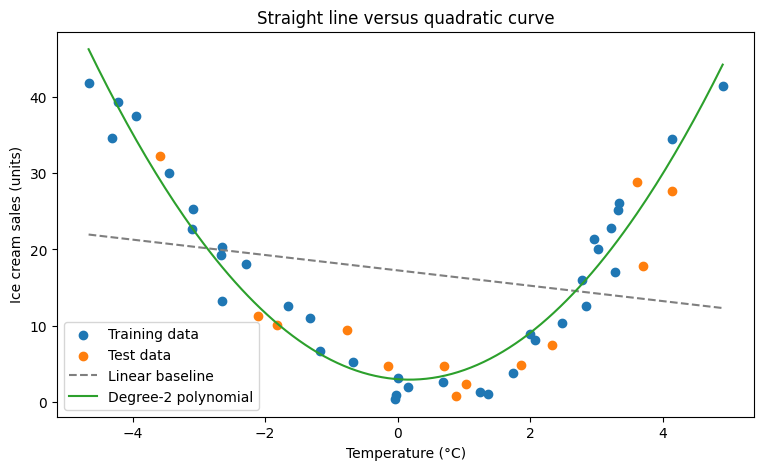

In [11]:
temperature_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
linear_curve = linear_model.predict(temperature_grid)
polynomial_curve = model.predict(polynomial_features.transform(temperature_grid))

plt.figure(figsize=(9, 5))
plt.scatter(X_train[:, 0], y_train, color="tab:blue", label="Training data")
plt.scatter(X_test[:, 0], y_test, color="tab:orange", label="Test data")
plt.plot(temperature_grid[:, 0], linear_curve, color="tab:gray", linestyle="--", label="Linear baseline")
plt.plot(temperature_grid[:, 0], polynomial_curve, color="tab:green", label="Degree-2 polynomial")
plt.xlabel("Temperature (°C)")
plt.ylabel("Ice cream sales (units)")
plt.title("Straight line versus quadratic curve")
plt.legend()
plt.show()

## 7. Predict sales for a new temperature

A new temperature must pass through the same fitted feature transformer before
prediction. The example below uses 2°C, which is inside the observed range of
approximately -4.66°C to 4.90°C. A polynomial can change rapidly outside the
observed range, so this example does not validate extrapolation.

In [12]:
new_temperature = np.array([[2.0]])
new_temperature_poly = polynomial_features.transform(new_temperature)
predicted_sales = model.predict(new_temperature_poly)[0]
print(f"Predicted sales at {new_temperature[0, 0]:.1f}°C: {predicted_sales:.2f} units")

Predicted sales at 2.0°C: 9.07 units
